# **BAGIAN C**



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [2]:
df = pd.read_excel("TugasBagianA_Bersih.xlsx", sheet_name="Data_Bersih")

df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"])
df["Month"] = df["Purchase_Date"].dt.month
df["Day_of_Month"] = df["Purchase_Date"].dt.day

df.head()

,Transaction_ID,Customer_ID,Age,Gender,City,Region,Membership_Level,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percentage,Purchase_Amount,Payment_Method,Store_Type,Purchase_Date,Purchase_Hour,Purchase_Day,Customer_Satisfaction,Month,Day_of_Month
0,TRX-000001,CUST-02118,35,Female,Jakarta,Jabodetabek,Gold,Groceries,Assorted Snack Box,5,104000,0.00,520000,QRIS,Online App,2026-01-01,3,Thursday,3,1,1
1,TRX-000002,CUST-03099,26,Male,Yogyakarta,Central Java,Basic,Home & Living,Air Purifier Mini,2,304000,0.20,486400,Credit Card,Online App,2026-01-01,5,Thursday,1,1,1
2,TRX-000003,CUST-01259,37,Female,Sidoarjo,East Java,Basic,Fashion,Casual Chino Pants,2,427000,0.10,768600,E-Wallet,Online App,2026-01-01,8,Thursday,1,1,1
3,TRX-000004,CUST-02153,33,Male,Medan,Sumatera,Premium,Home & Living,Ceramic Coffee Dripper,3,426000,0.05,1214100,E-Wallet,Official Web,2026-01-01,8,Thursday,4,1,1
4,TRX-000005,CUST-00942,31,Male,Tangerang,Jabodetabek,Basic,Beauty & Health,Hydrating Facial Cleanser,3,92000,0.05,262200,Debit Card,Flagship Store,2026-01-01,8,Thursday,5,1,1


In [3]:
print("Ukuran data :", df.shape)
print("Missing     :", df.isnull().sum().sum())
print("Maks diskon :", df["Discount_Percentage"].max())

Ukuran data : (9557, 21)
Missing     : 0
Maks diskon : 0.5


# **SOAL 1: DINAMIKA WAKTU BELANJA**
> **Pertanyaan 1:** Bagaimana tren volume transaksi harian sepanjang bulan, serta jam dan hari apa yang menjadi puncak aktivitas belanja? Apakah terdapat lonjakan transaksi pada rentang tanggal tertentu setiap bulannya?

In [4]:
import os
import matplotlib.dates as mdates

os.makedirs("charts", exist_ok=True)

## **GRAFIK 1.1 | Tren Volume Transaksi Harian Sepanjang 2026**

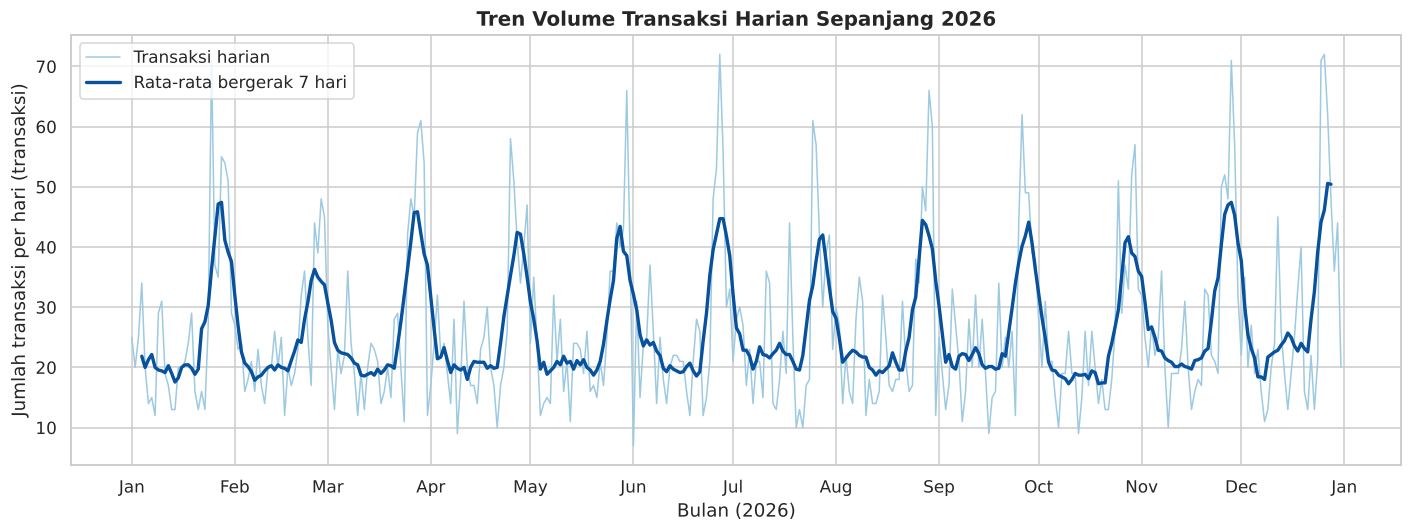

In [5]:
harian = df.groupby("Purchase_Date").size().rename("Transaksi").reset_index()
harian["MA7"] = harian["Transaksi"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(harian["Purchase_Date"], harian["Transaksi"], color="#9ecae1", linewidth=1, label="Transaksi harian")
ax.plot(harian["Purchase_Date"], harian["MA7"], color="#08519c", linewidth=2.2, label="Rata-rata bergerak 7 hari")
ax.set_title("Tren Volume Transaksi Harian Sepanjang 2026", fontsize=13, fontweight="bold")
ax.set_xlabel("Bulan (2026)")
ax.set_ylabel("Jumlah transaksi per hari (transaksi)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tren_harian.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 1.1 (Tren harian).** Volume transaksi harian membentuk siklus yang berulang setiap bulan: rata-rata 7 hari naik tajam menjelang akhir bulan (puncak bulanan sekitar 36 sampai 51 transaksi per hari), lalu turun ke kisaran 17-20 transaksi per hari. Rata-rata harian sepanjang 2026 sekitar 26 transaksi, dan puncak tertinggi terjadi pada akhir Desember. Pola yang berulang ini penting secara bisnis karena kebutuhan stok, kurir, dan layanan pelanggan sangat tidak merata sepanjang bulan.

## **GRAFIK 1.2 | Rata-rata Transaksi per Hari Berdasarkan Tanggal dalam Bulan**

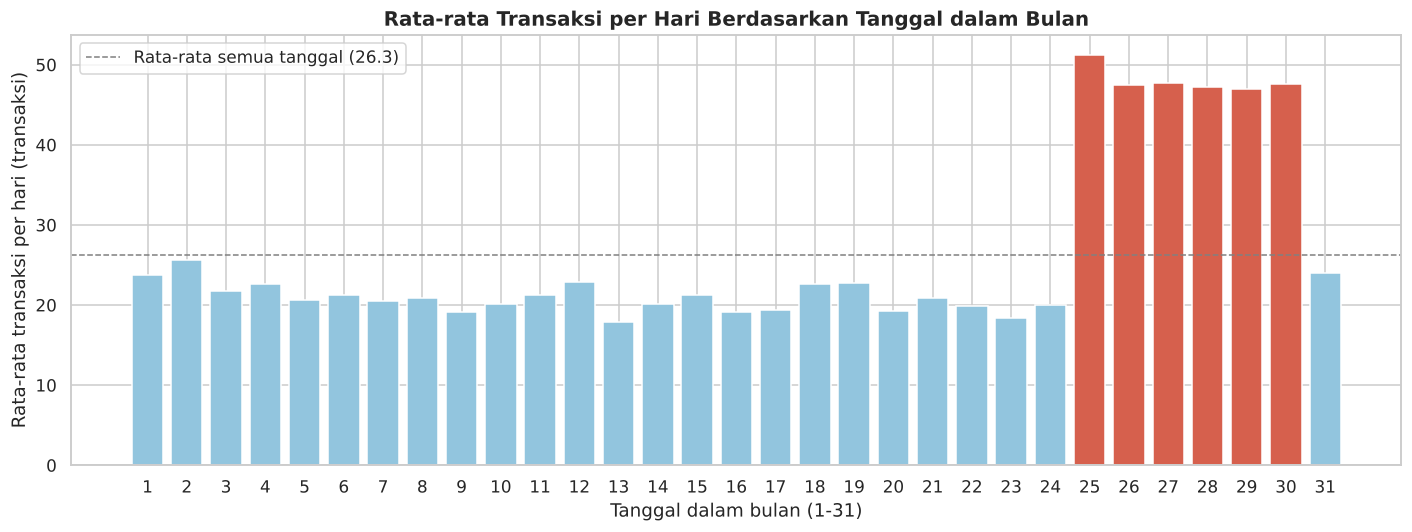

In [6]:
per_tanggal = harian.groupby(harian["Purchase_Date"].dt.day)["Transaksi"].mean()
batas = per_tanggal.mean() * 1.15
warna = ["#d6604d" if v >= batas else "#92c5de" for v in per_tanggal.values]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(per_tanggal.index, per_tanggal.values, color=warna)
ax.axhline(per_tanggal.mean(), color="gray", linestyle="--", linewidth=1,
           label=f"Rata-rata semua tanggal ({per_tanggal.mean():.1f})")
ax.set_title("Rata-rata Transaksi per Hari Berdasarkan Tanggal dalam Bulan", fontsize=13, fontweight="bold")
ax.set_xlabel("Tanggal dalam bulan (1-31)")
ax.set_ylabel("Rata-rata transaksi per hari (transaksi)")
ax.set_xticks(range(1, 32))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tanggal_dalam_bulan.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 1.2 (Tanggal dalam bulan).** Tanggal 25-30 rata-rata mencatat 47-51 transaksi per hari, lebih dari dua kali lipat dibanding tanggal lain yang hanya sekitar 18-26 transaksi, dan tanggal 31 kembali turun ke sekitar 24. Lonjakan ini muncul di seluruh 12 bulan dan diduga terkait waktu gajian, tetapi data tidak dapat membuktikan penyebabnya. Secara bisnis, promo, stok, dan kapasitas layanan perlu difokuskan pada tanggal 25-30 setiap bulan.

## **GRAFIK 1.3 | Heatmap Jumlah Transaksi: Hari x Jam**

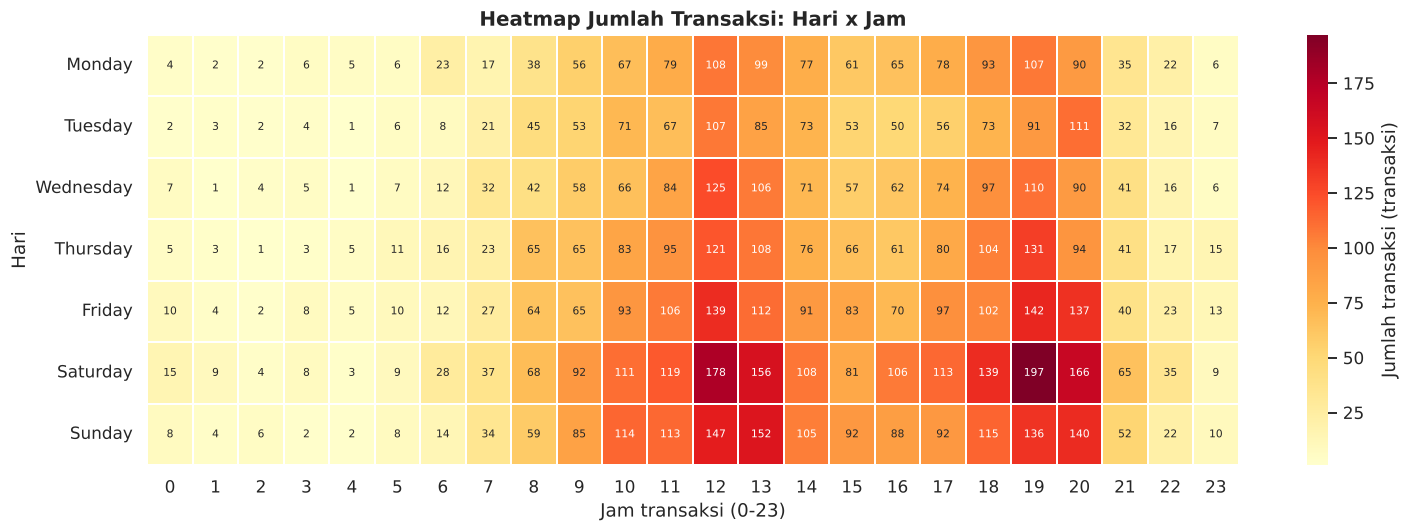

In [7]:
urutan_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = (df.pivot_table(index="Purchase_Day", columns="Purchase_Hour",
                        values="Transaction_ID", aggfunc="count", fill_value=0)
           .reindex(urutan_hari).reindex(columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt="d", annot_kws={"size": 7}, linewidths=0.3,
            cbar_kws={"label": "Jumlah transaksi (transaksi)"}, ax=ax)
ax.set_title("Heatmap Jumlah Transaksi: Hari x Jam", fontsize=13, fontweight="bold")
ax.set_xlabel("Jam transaksi (0-23)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("charts/H1_heatmap_hari_jam.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 1.3 (Heatmap hari x jam).** Sabtu adalah hari tersibuk (1.856 transaksi), disusul Minggu (1.600) dan Jumat (1.455), sedangkan Selasa paling sepi (1.037). Puncak jam terjadi pada pukul 12.00 (925 transaksi) dan 19.00 (914), dengan sel tersibuk Sabtu pukul 19.00 (197 transaksi). Pukul 01.00-04.00 sangat sepi (total 105 transaksi), meskipun sebagian dipengaruhi pembersihan data yang mengeluarkan transaksi gerai fisik pada jam 00-07 dan 23. Promo kilat dan penjadwalan staf sebaiknya mengikuti pola akhir pekan serta jam makan siang dan malam.

# **SOAL 2: KONTRIBUSI GEOGRAFIS**
> **Pertanyaan brief:** Wilayah (`Region`) mana yang menyumbang volume dan nilai transaksi tertinggi, dan bagaimana kontribusi masing-masing kota (`City`) di dalam wilayah tersebut?

In [8]:
from matplotlib.patches import Patch

def fmt_id(x, nd=0):
    """Format angka gaya Indonesia: titik ribuan, koma desimal."""
    return f"{x:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

region = (df.groupby("Region")
            .agg(Transaksi=("Transaction_ID", "count"), Nilai=("Purchase_Amount", "sum"))
            .sort_values("Nilai", ascending=False))
region["Nilai_M"] = region["Nilai"] / 1e9
region["Pct_Trx"] = region["Transaksi"] / region["Transaksi"].sum() * 100
region["Pct_Nilai"] = region["Nilai"] / region["Nilai"].sum() * 100

urut_region = region.index.tolist()
warna_region = dict(zip(urut_region, sns.color_palette("colorblind", len(urut_region))))

region.round(2)

,Transaksi,Nilai,Nilai_M,Pct_Trx,Pct_Nilai
Region,,,,,
Jabodetabek,3932,6893969150,6.89,41.14,36.19
West Java,1650,3381092550,3.38,17.26,17.75
East Java,1518,3349590850,3.35,15.88,17.58
Central Java,1467,3102443050,3.10,15.35,16.29
Sumatera,990,2322451000,2.32,10.36,12.19


## **GRAFIK 2.1 | Kontribusi Wilayah terhadap Volume dan Nilai Transaksi 2026**

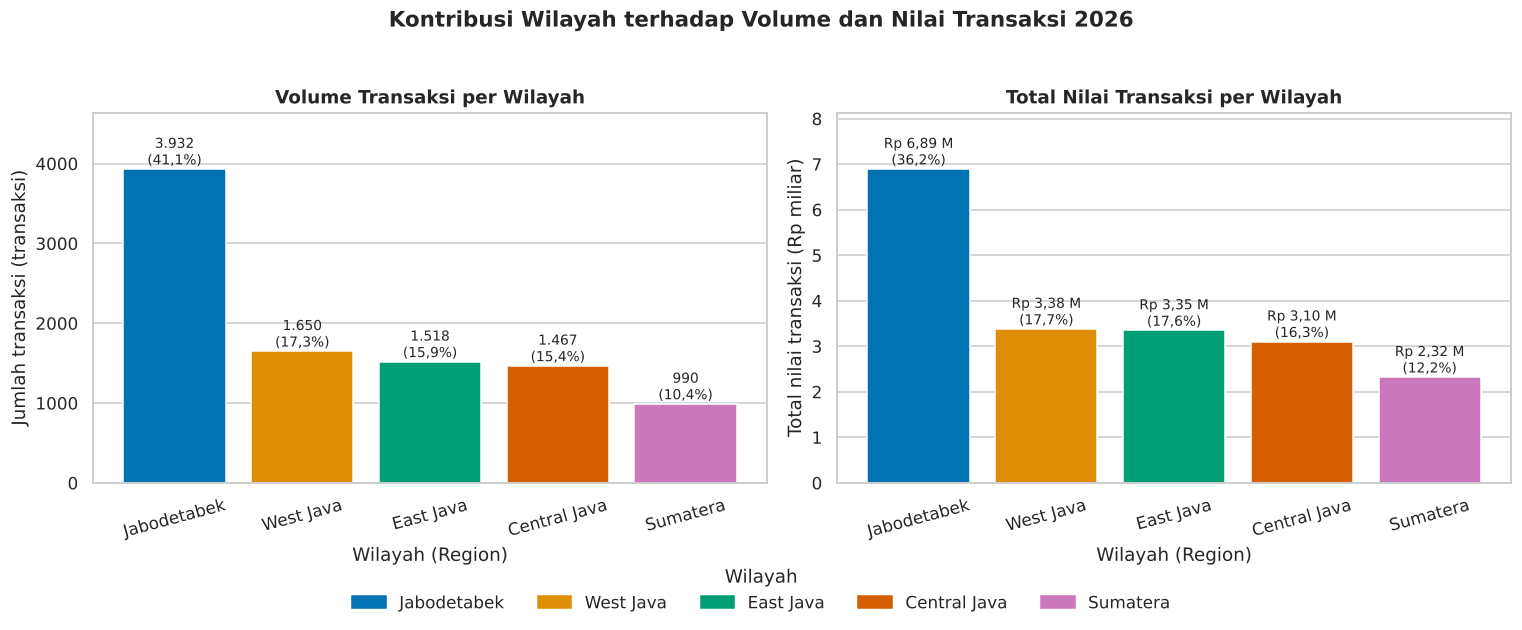

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].bar(urut_region, region["Transaksi"], color=[warna_region[r] for r in urut_region])
for i, r in enumerate(urut_region):
    axes[0].text(i, region.loc[r, "Transaksi"],
                 f"{fmt_id(region.loc[r, 'Transaksi'])}\n({fmt_id(region.loc[r, 'Pct_Trx'], 1)}%)",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_title("Volume Transaksi per Wilayah", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Wilayah (Region)")
axes[0].set_ylabel("Jumlah transaksi (transaksi)")
axes[0].set_ylim(0, region["Transaksi"].max() * 1.18)

axes[1].bar(urut_region, region["Nilai_M"], color=[warna_region[r] for r in urut_region])
for i, r in enumerate(urut_region):
    axes[1].text(i, region.loc[r, "Nilai_M"],
                 f"Rp {fmt_id(region.loc[r, 'Nilai_M'], 2)} M\n({fmt_id(region.loc[r, 'Pct_Nilai'], 1)}%)",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_title("Total Nilai Transaksi per Wilayah", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Wilayah (Region)")
axes[1].set_ylabel("Total nilai transaksi (Rp miliar)")
axes[1].set_ylim(0, region["Nilai_M"].max() * 1.18)

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(False, axis="x")

fig.legend(handles=[Patch(color=warna_region[r], label=r) for r in urut_region],
           title="Wilayah", loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04), frameon=False)
fig.suptitle("Kontribusi Wilayah terhadap Volume dan Nilai Transaksi 2026", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("charts/H2_region_volume_nilai.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 2.1 (Wilayah).** Jabodetabek tertinggi pada volume (3.932 transaksi, 41,1%) maupun nilai (Rp 6,89 miliar, 36,2% dari total Rp 19,05 miliar). West Java, East Java, dan Central Java nilainya berdekatan (16,3%-17,7%), sedangkan Sumatera terendah (990 transaksi, Rp 2,32 miliar). Porsi nilai Jabodetabek lebih kecil daripada porsi volumenya, artinya nilai per transaksi di sana relatif lebih rendah. Perlu dicatat bahwa Jabodetabek memiliki lima kota sedangkan wilayah lain tiga, sehingga sebagian selisih total berasal dari jumlah kota.

## **GRAFIK 2.2 | Kontribusi Kota terhadap Total Nilai Transaksi di Tiap Wilayah**

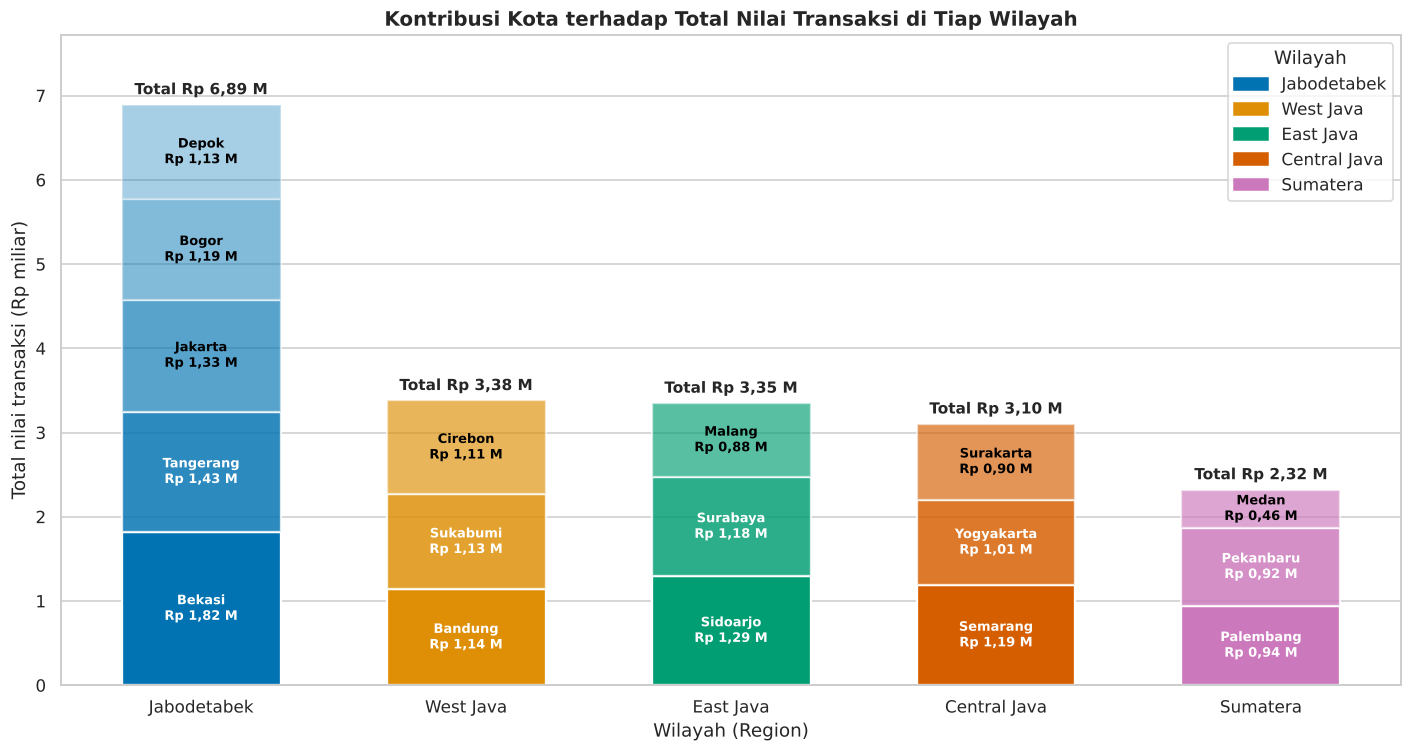

In [10]:
kota = (df.groupby(["Region", "City"])["Purchase_Amount"].sum().div(1e9)
          .rename("Nilai_M").reset_index())

fig, ax = plt.subplots(figsize=(13, 7))
for i, r in enumerate(urut_region):
    sub = kota[kota["Region"] == r].sort_values("Nilai_M", ascending=False)
    bawah = 0
    for j, (_, baris) in enumerate(sub.iterrows()):
        alpha = max(1.0 - j * 0.17, 0.35)
        ax.bar(i, baris["Nilai_M"], bottom=bawah, color=warna_region[r], alpha=alpha,
               edgecolor="white", linewidth=1.5, width=0.6)
        ax.text(i, bawah + baris["Nilai_M"] / 2,
                f"{baris['City']}\nRp {fmt_id(baris['Nilai_M'], 2)} M",
                ha="center", va="center", fontsize=8.5,
                color="black" if alpha < 0.7 else "white", fontweight="bold")
        bawah += baris["Nilai_M"]
    ax.text(i, bawah + 0.08, f"Total Rp {fmt_id(bawah, 2)} M",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(urut_region)))
ax.set_xticklabels(urut_region)
ax.set_xlabel("Wilayah (Region)")
ax.set_ylabel("Total nilai transaksi (Rp miliar)")
ax.set_title("Kontribusi Kota terhadap Total Nilai Transaksi di Tiap Wilayah", fontsize=13, fontweight="bold")
ax.set_ylim(0, region["Nilai_M"].max() * 1.12)
ax.grid(False, axis="x")
ax.legend(handles=[Patch(color=warna_region[r], label=r) for r in urut_region], title="Wilayah", loc="upper right")
plt.tight_layout()
plt.savefig("charts/H2_kota_per_region.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 2.2 (Kota di dalam wilayah).** Di Jabodetabek, Bekasi menyumbang nilai terbesar (Rp 1,82 miliar, 26,4% dari nilai wilayah), disusul Tangerang (20,7%), Jakarta (19,3%), Bogor (17,3%), dan Depok (16,3%). Depok memiliki transaksi terbanyak (917) namun nilainya terkecil di antara lima kota tersebut, sehingga banyaknya transaksi tidak otomatis berarti besarnya nilai. Di luar Jabodetabek, tiap kota menyumbang 26-41% nilai wilayahnya (West Java hampir merata, sekitar sepertiga per kota), kecuali Medan yang hanya 19,6% dan merupakan kota dengan nilai terkecil dari seluruh kota (Rp 0,46 miliar). Strategi perlu dibedakan per kota: meningkatkan nilai per transaksi di Depok dan memperluas jangkauan di Medan.

## **TABEL 2.3 | Ringkasan Kontribusi Kota per Wilayah**

In [11]:
tabel = (df.groupby(["Region", "City"])
           .agg(Transaksi=("Transaction_ID", "count"), Nilai=("Purchase_Amount", "sum"))
           .reset_index())
tabel["Pct_trx_dlm_wilayah"] = (tabel["Transaksi"] / tabel.groupby("Region")["Transaksi"].transform("sum") * 100).round(1)
tabel["Pct_nilai_dlm_wilayah"] = (tabel["Nilai"] / tabel.groupby("Region")["Nilai"].transform("sum") * 100).round(1)
tabel["Nilai_Rp_miliar"] = (tabel["Nilai"] / 1e9).round(2)
tabel = tabel.drop(columns="Nilai").sort_values(["Region", "Nilai_Rp_miliar"], ascending=[True, False])
tabel

,Region,City,Transaksi,Pct_trx_dlm_wilayah,Pct_nilai_dlm_wilayah,Nilai_Rp_miliar
0,Central Java,Semarang,550,37.5,38.3,1.19
2,Central Java,Yogyakarta,496,33.8,32.6,1.01
1,Central Java,Surakarta,421,28.7,29.1,0.90
4,East Java,Sidoarjo,504,33.2,38.7,1.29
5,East Java,Surabaya,501,33.0,35.1,1.18
3,East Java,Malang,513,33.8,26.2,0.88
6,Jabodetabek,Bekasi,757,19.3,26.4,1.82
10,Jabodetabek,Tangerang,730,18.6,20.7,1.43
9,Jabodetabek,Jakarta,759,19.3,19.3,1.33
7,Jabodetabek,Bogor,769,19.6,17.3,1.19


*Tabel di atas melengkapi Grafik 2.2: jumlah transaksi, kontribusi transaksi dan nilai tiap kota di dalam wilayahnya, serta nilai dalam Rp miliar.*

# **SOAL 3: PENGARUH MEMBERSHIP DAN KATEGORI PRODUK**
> **Pertanyaan brief:** Apakah pelanggan dengan tingkat `Membership_Level` lebih tinggi membelanjakan uang lebih banyak dibanding tier di bawahnya? Kategori produk (`Product_Category`) mana yang memiliki nilai transaksi terbesar? (Grafik harus mampu memperlihatkan sebaran data, bukan sekadar rata-rata.)

In [12]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

def rp_singkat(x, _):
    if x >= 1e9: return f"{x/1e9:g} M"
    if x >= 1e6: return f"{x/1e6:g} jt"
    if x >= 1e3: return f"{x/1e3:g} rb"
    return f"{x:g}"

urut_member = ["Basic", "Silver", "Gold", "Premium"]
warna_member = dict(zip(urut_member, sns.color_palette("YlGnBu", 6)[1:5]))

mean_props = dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6)
flier_props = dict(marker="o", markersize=2.5, alpha=0.35, markerfacecolor="gray", markeredgecolor="none")
legenda_box = [
    Line2D([0], [0], color="black", linewidth=2, label="Median (garis tengah kotak)"),
    Line2D([0], [0], marker="D", color="w", markerfacecolor="white", markeredgecolor="black", markersize=7, label="Rata-rata"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", alpha=0.6, markersize=5, label="Outlier (metode IQR)"),
]

## **GRAFIK 3.1 | Sebaran Nilai Transaksi Berdasarkan Level Membership**

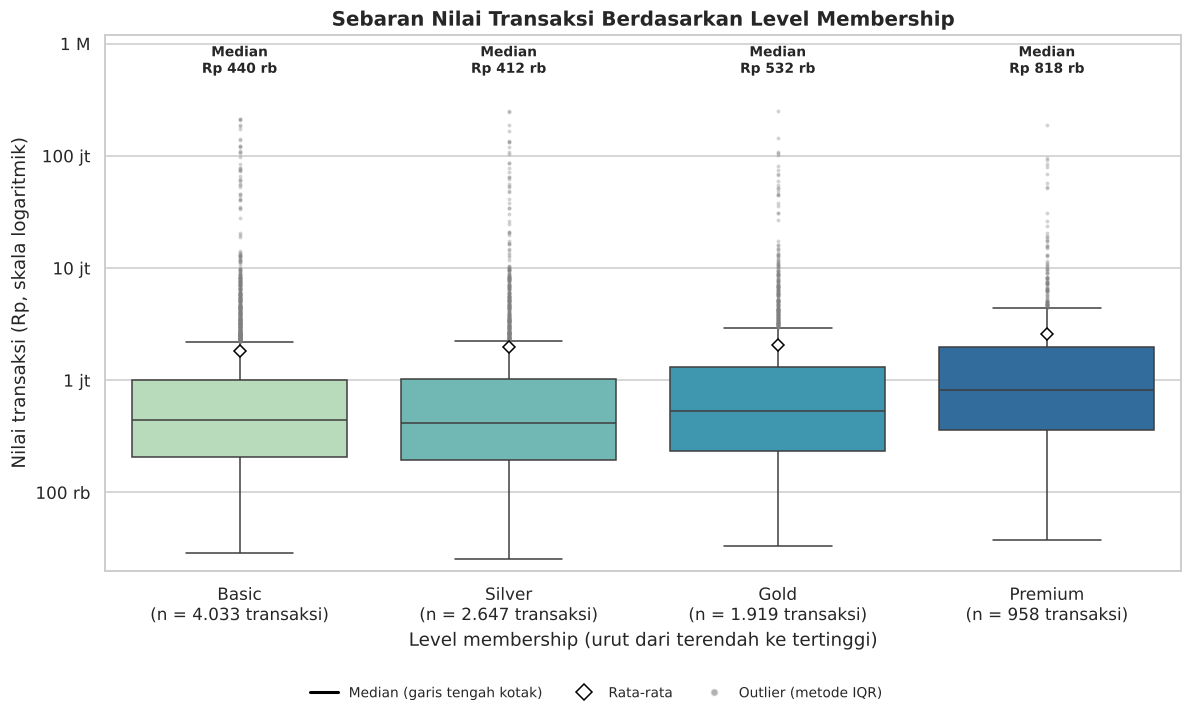

In [13]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.boxplot(data=df, x="Membership_Level", y="Purchase_Amount", order=urut_member,
            hue="Membership_Level", hue_order=urut_member, palette=warna_member, legend=False,
            showmeans=True, meanprops=mean_props, flierprops=flier_props, ax=ax)
ax.set_yscale("log")
ax.set_ylim(2e4, 1.2e9)
ax.yaxis.set_major_formatter(FuncFormatter(rp_singkat))

n_per = df["Membership_Level"].value_counts()
med_per = df.groupby("Membership_Level")["Purchase_Amount"].median()
ax.set_xticks(range(4))
ax.set_xticklabels([f"{m}\n(n = {fmt_id(n_per[m])} transaksi)" for m in urut_member])
for i, m in enumerate(urut_member):
    ax.text(i, 5e8, f"Median\nRp {fmt_id(med_per[m] / 1e3)} rb", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title("Sebaran Nilai Transaksi Berdasarkan Level Membership", fontsize=13, fontweight="bold")
ax.set_xlabel("Level membership (urut dari terendah ke tertinggi)")
ax.set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
fig.legend(handles=legenda_box, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("charts/H3_boxplot_membership.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 3.1 (Membership).** Median nilai transaksi Basic Rp 440 ribu, Silver Rp 412 ribu, Gold Rp 532 ribu, dan Premium Rp 818 ribu. Jadi hipotesis manajemen hanya sebagian benar: Gold dan Premium belanja lebih besar dari tier di bawahnya, tetapi Silver tidak lebih tinggi dari Basic. Sebaran tiap tier juga banyak tumpang tindih (bagian atas kotak Basic, sekitar Rp 1 juta, sudah di atas median Premium), sehingga level membership saja belum cukup menjelaskan besar belanja. Rata-rata (◆) berada jauh di atas median pada semua tier karena pengaruh outlier, sehingga median lebih tepat untuk mewakili belanja tipikal. Sumbu Y memakai skala logaritmik.

## **GRAFIK 3.2 | Nilai Transaksi Berdasarkan Kategori Produk**

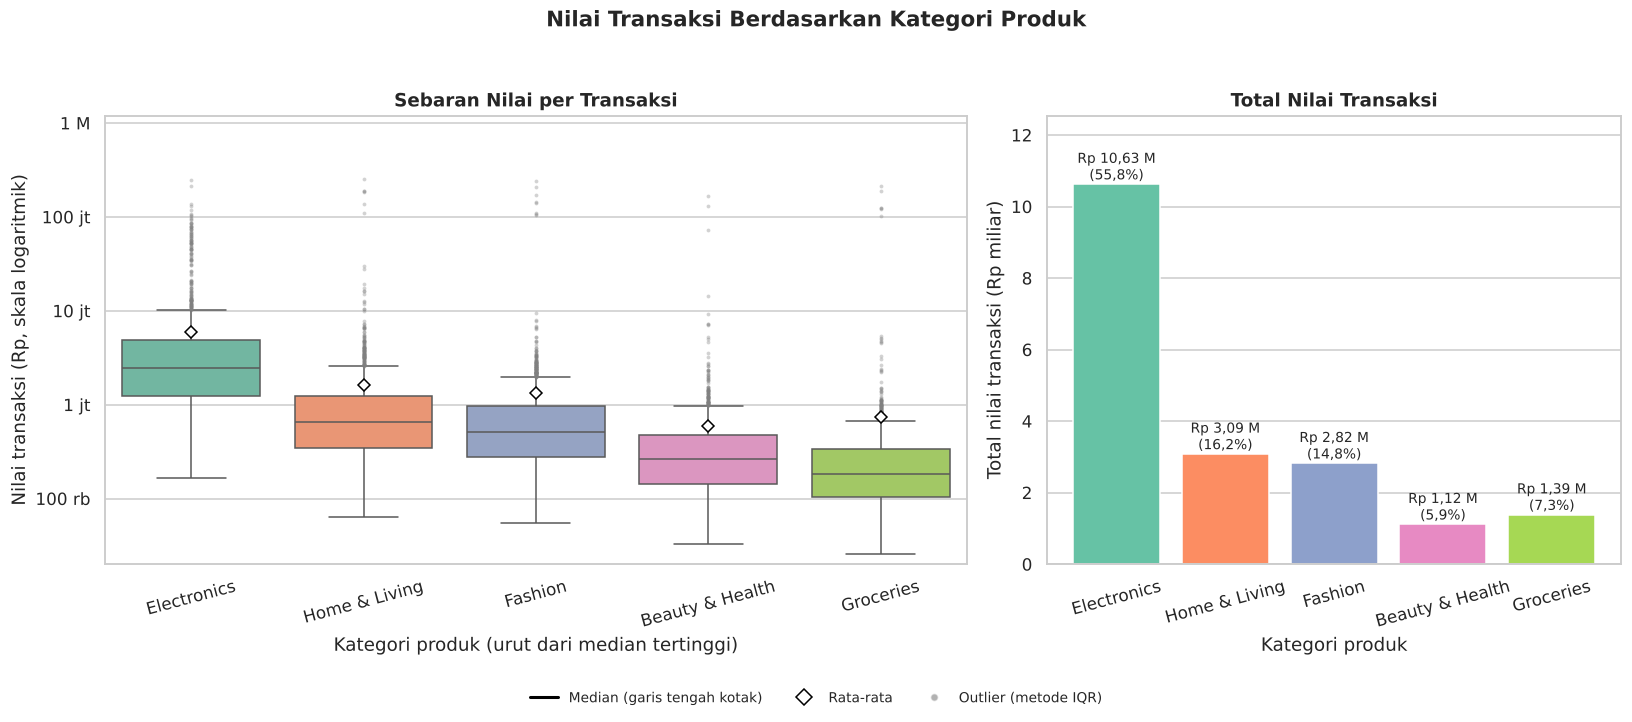

In [14]:
urut_kat = df.groupby("Product_Category")["Purchase_Amount"].median().sort_values(ascending=False).index.tolist()
warna_kat = dict(zip(urut_kat, sns.color_palette("Set2", len(urut_kat))))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})

sns.boxplot(data=df, x="Product_Category", y="Purchase_Amount", order=urut_kat,
            hue="Product_Category", hue_order=urut_kat, palette=warna_kat, legend=False,
            showmeans=True, meanprops=mean_props, flierprops=flier_props, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_ylim(2e4, 1.2e9)
axes[0].yaxis.set_major_formatter(FuncFormatter(rp_singkat))
axes[0].set_title("Sebaran Nilai per Transaksi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Kategori produk (urut dari median tertinggi)")
axes[0].set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
axes[0].tick_params(axis="x", rotation=15)

total = (df.groupby("Product_Category")["Purchase_Amount"].sum() / 1e9).reindex(urut_kat)
pct = total / total.sum() * 100
axes[1].bar(urut_kat, total.values, color=[warna_kat[k] for k in urut_kat])
for i, k in enumerate(urut_kat):
    axes[1].text(i, total[k], f"Rp {fmt_id(total[k], 2)} M\n({fmt_id(pct[k], 1)}%)", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, total.max() * 1.18)
axes[1].set_title("Total Nilai Transaksi", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kategori produk")
axes[1].set_ylabel("Total nilai transaksi (Rp miliar)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(False, axis="x")

fig.suptitle("Nilai Transaksi Berdasarkan Kategori Produk", fontsize=14, fontweight="bold")
fig.legend(handles=legenda_box, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig("charts/H3_boxplot_kategori.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 3.2 (Kategori produk).** Electronics memiliki nilai per transaksi tertinggi (median sekitar Rp 2,46 juta, lihat Tabel 3.3 di bawah) dan kontribusi total terbesar, yaitu Rp 10,63 miliar atau 55,8% dari seluruh nilai transaksi. Kategori lain jauh di bawahnya: Home & Living 16,2%, Fashion 14,8%, Groceries 7,3%, dan Beauty & Health 5,9%. Pada Groceries, rata-rata (◆) jauh di atas median, menandakan adanya beberapa transaksi pembelian besar. Dari sisi bisnis, performa omzet sangat bergantung pada kategori Electronics.

## **TABEL 3.3 | Median Nilai Transaksi per Kategori Produk**

In [15]:
df.groupby("Product_Category")["Purchase_Amount"].median().sort_values(ascending=False)

Product_Category
Electronics        2459850.0
Home & Living       660400.0
Fashion             513000.0
Beauty & Health     265600.0
Groceries           184750.0
Name: Purchase_Amount, dtype: float64

# **SOAL 4: KORELASI KEPUASAN PELANGGAN**
> **Pertanyaan brief:** Apakah pelanggan dengan skor `Customer_Satisfaction` tinggi (4 dan 5) cenderung melakukan pembelian dengan nilai `Purchase_Amount` yang lebih besar dibandingkan pelanggan yang kurang puas (skor 1 dan 2)?

In [16]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def rp_pendek(x):
    return f"Rp {fmt_id(x / 1e6, 2)} jt" if x >= 1e6 else f"Rp {fmt_id(x / 1e3)} rb"

df["log_amount"] = np.log10(df["Purchase_Amount"])
df["Kelompok_Puas"] = pd.cut(df["Customer_Satisfaction"], bins=[0, 2, 3, 5],
                             labels=["Kurang puas (1-2)", "Netral (3)", "Puas (4-5)"])

# Spearman = korelasi Pearson pada peringkat (tidak butuh scipy)
rho = df["Customer_Satisfaction"].rank().corr(df["Purchase_Amount"].rank())
skor = [1, 2, 3, 4, 5]
warna_skor = dict(zip(skor, sns.color_palette("RdYlBu", 5)))
n_skor = df["Customer_Satisfaction"].value_counts()
med_skor = df.groupby("Customer_Satisfaction")["Purchase_Amount"].median()

print("Korelasi Spearman:", round(rho, 4))

Korelasi Spearman: 0.0929


## **GRAFIK 4.1 | Sebaran Nilai Transaksi menurut Skor Kepuasan Pelanggan**

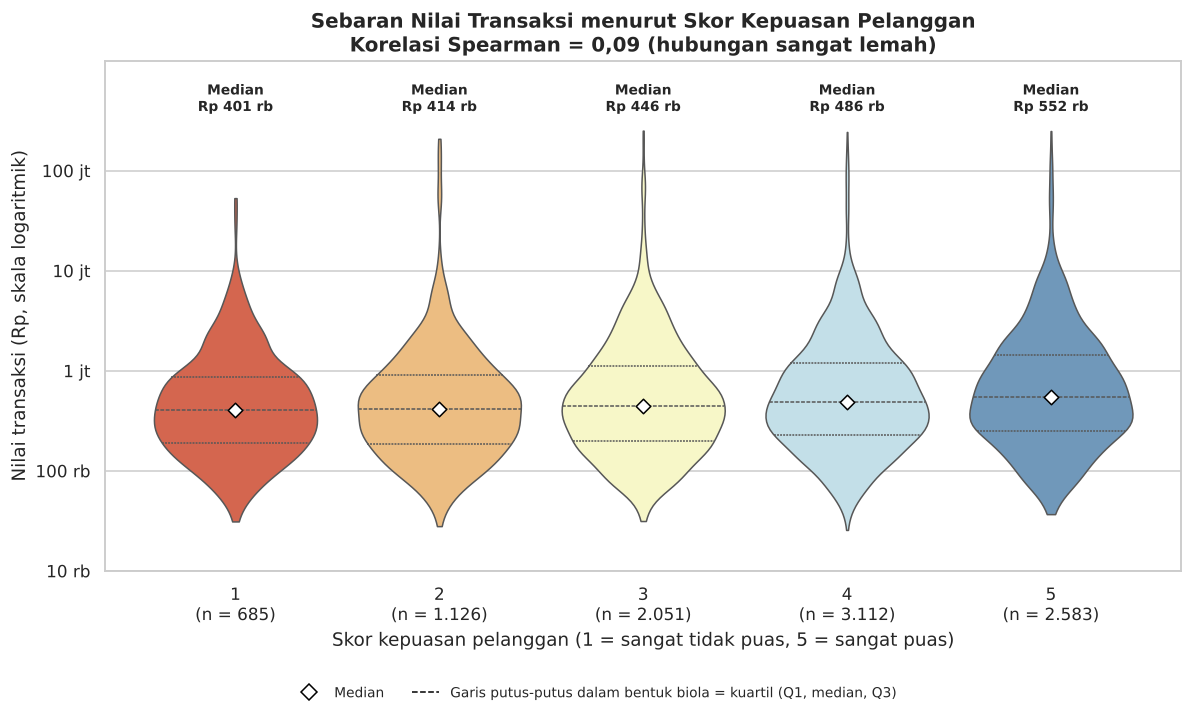

In [17]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.violinplot(data=df, x="Customer_Satisfaction", y="log_amount", order=skor,
               hue="Customer_Satisfaction", hue_order=skor, palette=warna_skor, legend=False,
               inner="quart", cut=0, linewidth=1, ax=ax)
ax.scatter(range(5), np.log10(med_skor.reindex(skor).values), marker="D", s=45,
           color="white", edgecolor="black", zorder=5)
for i, s in enumerate(skor):
    ax.text(i, 8.55, f"Median\n{rp_pendek(med_skor[s])}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylim(4.2, 9.1)
ax.set_yticks([4, 5, 6, 7, 8])
ax.set_yticklabels(["10 rb", "100 rb", "1 jt", "10 jt", "100 jt"])
ax.set_xticks(range(5))
ax.set_xticklabels([f"{s}\n(n = {fmt_id(n_skor[s])})" for s in skor])
ax.set_xlabel("Skor kepuasan pelanggan (1 = sangat tidak puas, 5 = sangat puas)")
ax.set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
ax.set_title(f"Sebaran Nilai Transaksi menurut Skor Kepuasan Pelanggan\nKorelasi Spearman = {fmt_id(rho, 2)} (hubungan sangat lemah)",
             fontsize=13, fontweight="bold")
legenda = [Line2D([0], [0], marker="D", color="w", markerfacecolor="white", markeredgecolor="black", markersize=7, label="Median"),
           Line2D([0], [0], color="black", linestyle="--", linewidth=1, label="Garis putus-putus dalam bentuk biola = kuartil (Q1, median, Q3)")]
fig.legend(handles=legenda, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("charts/H4_violin_kepuasan.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 4.1 (Sebaran per skor).** Median nilai transaksi naik seiring skor kepuasan: Rp 401 ribu (skor 1), Rp 414 ribu, Rp 446 ribu, Rp 486 ribu, hingga Rp 552 ribu (skor 5). Kelompok puas (skor 4-5) bermedian Rp 512 ribu, sekitar 25% lebih tinggi daripada kelompok kurang puas (skor 1-2) yang Rp 411 ribu (lihat sel verifikasi di akhir notebook). Namun hubungannya sangat lemah (korelasi Spearman 0,09) dan sebaran semua skor saling tumpang tindih besar, sehingga skor kepuasan bukan penentu utama besar belanja. Spearman dipilih karena skor kepuasan bersifat ordinal dan nilai belanja sangat miring.

## **GRAFIK 4.2 | Selisih Median Nilai Transaksi: Pelanggan Puas (4-5) vs Kurang Puas (1-2), per Kategori Produk**

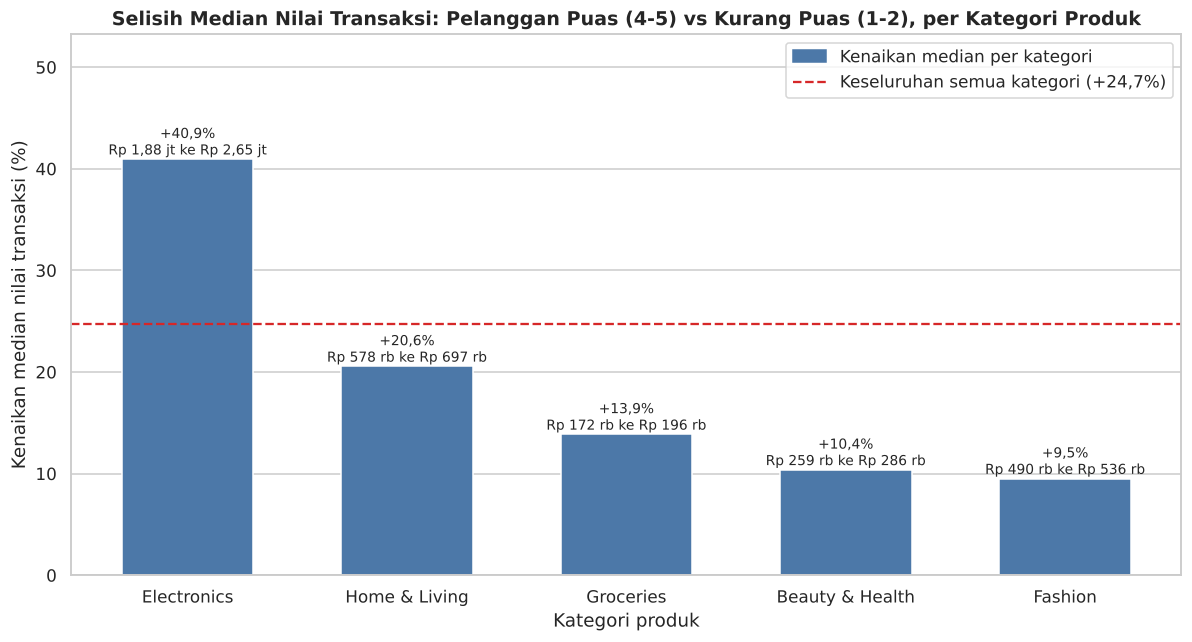

In [18]:
med = df.pivot_table(index="Product_Category", columns="Kelompok_Puas", values="Purchase_Amount",
                     aggfunc="median", observed=True)
uplift = ((med["Puas (4-5)"] / med["Kurang puas (1-2)"] - 1) * 100).sort_values(ascending=False)
overall = (df.loc[df["Customer_Satisfaction"] >= 4, "Purchase_Amount"].median() /
           df.loc[df["Customer_Satisfaction"] <= 2, "Purchase_Amount"].median() - 1) * 100

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(uplift.index, uplift.values, color="#4c78a8", width=0.6)
for i, k in enumerate(uplift.index):
    ax.text(i, uplift[k], f"+{fmt_id(uplift[k], 1)}%\n{rp_pendek(med.loc[k, 'Kurang puas (1-2)'])} ke {rp_pendek(med.loc[k, 'Puas (4-5)'])}",
            ha="center", va="bottom", fontsize=9)
ax.axhline(overall, color="#d62728", linestyle="--", linewidth=1.5)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(0, uplift.max() * 1.3)
ax.set_title("Selisih Median Nilai Transaksi: Pelanggan Puas (4-5) vs Kurang Puas (1-2), per Kategori Produk",
             fontsize=12.5, fontweight="bold")
ax.set_xlabel("Kategori produk")
ax.set_ylabel("Kenaikan median nilai transaksi (%)")
ax.grid(False, axis="x")
ax.legend(handles=[Patch(color="#4c78a8", label="Kenaikan median per kategori"),
                   Line2D([0], [0], color="#d62728", linestyle="--", label=f"Keseluruhan semua kategori (+{fmt_id(overall, 1)}%)")],
          loc="upper right")
plt.tight_layout()
plt.savefig("charts/H4_selisih_median_kategori.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 4.2 (Per kategori).** Pola yang sama muncul di kelima kategori: median transaksi pelanggan puas selalu lebih tinggi daripada pelanggan kurang puas, dari +9,5% (Fashion) hingga +40,9% (Electronics, Rp 1,88 juta menjadi Rp 2,65 juta), dan +24,7% secara keseluruhan. Karena pola ini terlihat di dalam tiap kategori, selisihnya tidak semata-mata disebabkan perbedaan jenis produk yang dibeli. Namun skor kepuasan dicatat setelah transaksi, sehingga data ini menunjukkan korelasi, bukan sebab-akibat, dan kepuasan sebaiknya dipantau sebagai indikator pendamping, bukan pendorong penjualan utama.

# **LAMPIRAN: Verifikasi Angka yang Dipakai pada Rekomendasi**
*Sel di bawah hanya menampilkan angka yang dikutip pada narasi dan rekomendasi, supaya setiap angka dapat ditelusuri ke data. Tidak ada analisis baru.*

In [19]:
# ---- Rekomendasi 1: waktu belanja ----
tgl = df["Purchase_Date"].dt.day
harian_s = df.groupby("Purchase_Date").size()
awal = harian_s[harian_s.index.day <= 24].mean()
akhir = harian_s[(harian_s.index.day >= 25) & (harian_s.index.day <= 30)].mean()
d2530 = df[(tgl >= 25) & (tgl <= 30)]

print("REKOMENDASI 1 (waktu belanja)")
print(f"Rata-rata transaksi/hari tgl 1-24 : {awal:.1f}")
print(f"Rata-rata transaksi/hari tgl 25-30: {akhir:.1f}  ({akhir / awal:.1f}x lipat)")
print(f"Porsi transaksi tgl 25-30         : {len(d2530) / len(df) * 100:.1f}%")
print(f"Porsi nilai tgl 25-30             : {d2530['Purchase_Amount'].sum() / df['Purchase_Amount'].sum() * 100:.1f}%")
print(f"Porsi transaksi Sabtu+Minggu      : {df['Purchase_Day'].isin(['Saturday', 'Sunday']).mean() * 100:.1f}%")
print(f"Porsi transaksi jam 12-13 & 19-20 : {df['Purchase_Hour'].isin([12, 13, 19, 20]).mean() * 100:.1f}%")
print(f"Target tgl 1-24 (+10%)            : {awal * 1.1:.1f}")

# apakah lonjakan tgl 25-30 muncul di setiap bulan?
rasio_bulan = {}
for b in range(1, 13):
    hb = harian_s[harian_s.index.month == b]
    rasio_bulan[b] = hb[(hb.index.day >= 25) & (hb.index.day <= 30)].mean() / hb[hb.index.day <= 24].mean()
print(f"Rasio tgl 25-30 vs tgl 1-24 per bulan: min {min(rasio_bulan.values()):.2f}x, maks {max(rasio_bulan.values()):.2f}x, "
      f"bulan dengan rasio > 1x: {sum(v > 1 for v in rasio_bulan.values())} dari 12")

# ---- Rekomendasi 2: wilayah dan kota ----
print("\nREKOMENDASI 2 (wilayah dan kota)")
kota_stat = df.groupby("City").agg(Transaksi=("Transaction_ID", "count"),
                                   Pelanggan_unik=("Customer_ID", "nunique"),
                                   Median_Rp=("Purchase_Amount", "median"))
print(kota_stat.loc[["Depok", "Bekasi", "Bogor", "Medan", "Pekanbaru"]])
print(f"Target median Depok (+10%)        : Rp {kota_stat.loc['Depok', 'Median_Rp'] * 1.1:,.0f}")
print(f"Target transaksi Medan (+30%)     : {kota_stat.loc['Medan', 'Transaksi'] * 1.3:.0f}")

# ---- Rekomendasi 3: membership dan kategori ----
print("\nREKOMENDASI 3 (membership dan kategori)")
med_member = df.groupby("Membership_Level")["Purchase_Amount"].median().reindex(["Basic", "Silver", "Gold", "Premium"])
print(med_member)
print(f"Kenaikan Silver ke level median Basic: +{(med_member['Basic'] / med_member['Silver'] - 1) * 100:.1f}%")
elektronik = df.loc[df["Product_Category"] == "Electronics", "Purchase_Amount"]
print(f"Electronics: porsi nilai {elektronik.sum() / df['Purchase_Amount'].sum() * 100:.1f}%, median Rp {elektronik.median():,.0f}")

# ---- Hipotesis 4: kelompok kepuasan ----
print("\nHIPOTESIS 4 (kepuasan)")
med_grup = df.groupby("Kelompok_Puas", observed=True)["Purchase_Amount"].median()
print(med_grup)
print(f"Median kelompok puas (4-5) vs kurang puas (1-2): +{(med_grup['Puas (4-5)'] / med_grup['Kurang puas (1-2)'] - 1) * 100:.1f}%")

REKOMENDASI 1 (waktu belanja)
Rata-rata transaksi/hari tgl 1-24 : 20.9
Rata-rata transaksi/hari tgl 25-30: 48.1  (2.3x lipat)
Porsi transaksi tgl 25-30         : 35.2%
Porsi nilai tgl 25-30             : 33.5%
Porsi transaksi Sabtu+Minggu      : 36.2%
Porsi transaksi jam 12-13 & 19-20 : 36.5%
Target tgl 1-24 (+10%)            : 23.0
Rasio tgl 25-30 vs tgl 1-24 per bulan: min 2.07x, maks 2.53x, bulan dengan rasio > 1x: 12 dari 12

REKOMENDASI 2 (wilayah dan kota)
           Transaksi  Pelanggan_unik  Median_Rp
City                                           
Depok            917             260   432000.0
Bekasi           757             233   475950.0
Bogor            769             233   475200.0
Medan            258              89   518000.0
Pekanbaru        374              96   453375.0
Target median Depok (+10%)        : Rp 475,200
Target transaksi Medan (+30%)     : 335

REKOMENDASI 3 (membership dan kategori)
Membership_Level
Basic      440300.0
Silver     412500.0
Gold       5

# **REKOMENDASI BISNIS**

## **Rekomendasi 1: Sinkronkan stok, promo, dan kapasitas dengan pola waktu belanja**
**Temuan:** Tanggal 25-30 (6 hari per bulan) menyumbang 35,2% transaksi dan 33,5% nilai, dengan rata-rata 48,1 transaksi per hari, atau 2,3 kali lipat dibanding tanggal 1-24 (20,9 transaksi per hari). Akhir pekan menyumbang 36,2% transaksi, dan hanya 4 jam (12-13 dan 19-20) menyumbang 36,5% transaksi.
**Aksi:** (a) Siapkan stok, kurir, layanan pelanggan, dan kapasitas aplikasi untuk tanggal 25-30. (b) Jalankan flash sale pada jam 12-13 dan 19-20 di akhir pekan. (c) Buat kampanye pemicu pada tanggal 1-24 supaya permintaan tidak menumpuk di akhir bulan.
**Target:** Naikkan rata-rata transaksi harian tanggal 1-24 dari 20,9 menjadi minimal 23 (+10%) dalam satu kuartal.
**Catatan:** Dugaan penyebab lonjakan adalah waktu gajian, tetapi data tidak bisa membuktikannya.

## **Rekomendasi 2: Naikkan nilai per transaksi di Depok dan perluas jangkauan di Medan**
**Temuan:** Jabodetabek menyumbang 41,1% transaksi tetapi hanya 36,2% nilai. Di dalamnya, Depok punya transaksi terbanyak (917) namun median terendah (Rp 432 ribu) dan kontribusi nilai terkecil (16,3%), sementara Bekasi dan Bogor mediannya sekitar Rp 475 ribu. Di Sumatera, Medan paling kecil (258 transaksi, 89 pelanggan unik), padahal median per transaksinya Rp 518 ribu, lebih tinggi dari Pekanbaru (Rp 453 ribu).
**Aksi:** Depok: bundling dan diskon bertingkat berdasarkan minimum belanja. Medan: promo pelanggan baru dan kerja sama kanal lokal.
**Target:** Median transaksi Depok dari Rp 432 ribu menjadi minimal Rp 475 ribu (setara Bekasi dan Bogor). Transaksi Medan dari 258 menjadi minimal 335 (+30%).
**Catatan:** KPI memakai median, bukan total nilai, karena total nilai per kota sensitif terhadap beberapa transaksi besar (outlier).

## **Rekomendasi 3: Rancang ulang manfaat tier Silver dan perkuat kategori Electronics**
**Temuan:** Median transaksi Silver (Rp 412 ribu) tidak lebih tinggi dari Basic (Rp 440 ribu), sedangkan Premium jauh lebih tinggi (Rp 818 ribu). Electronics menyumbang 55,8% dari total nilai transaksi dengan median per transaksi tertinggi (Rp 2,46 juta).
**Aksi:** Beri manfaat tier Silver yang terkait belanja (cashback atau voucher dengan syarat minimum belanja, terutama untuk kategori Electronics) agar naik ke Silver benar-benar mendorong belanja lebih besar.
**Target:** Median transaksi Silver naik dari Rp 412 ribu menjadi minimal Rp 440 ribu (setara Basic, +6,7%) dalam dua kuartal.
**Catatan:** Skor kepuasan cukup dipantau. Hubungannya dengan nilai belanja lemah (Spearman 0,09, tercantum pada Grafik 4.1), sehingga bukan pendorong penjualan utama.